<a href="https://colab.research.google.com/github/Angelinat3/Machine-Learning2026/blob/main/JS08/JS08_Lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Jumlah klaster: 2
Jumlah noise: 0
Label unik: {np.int64(0), np.int64(1)}


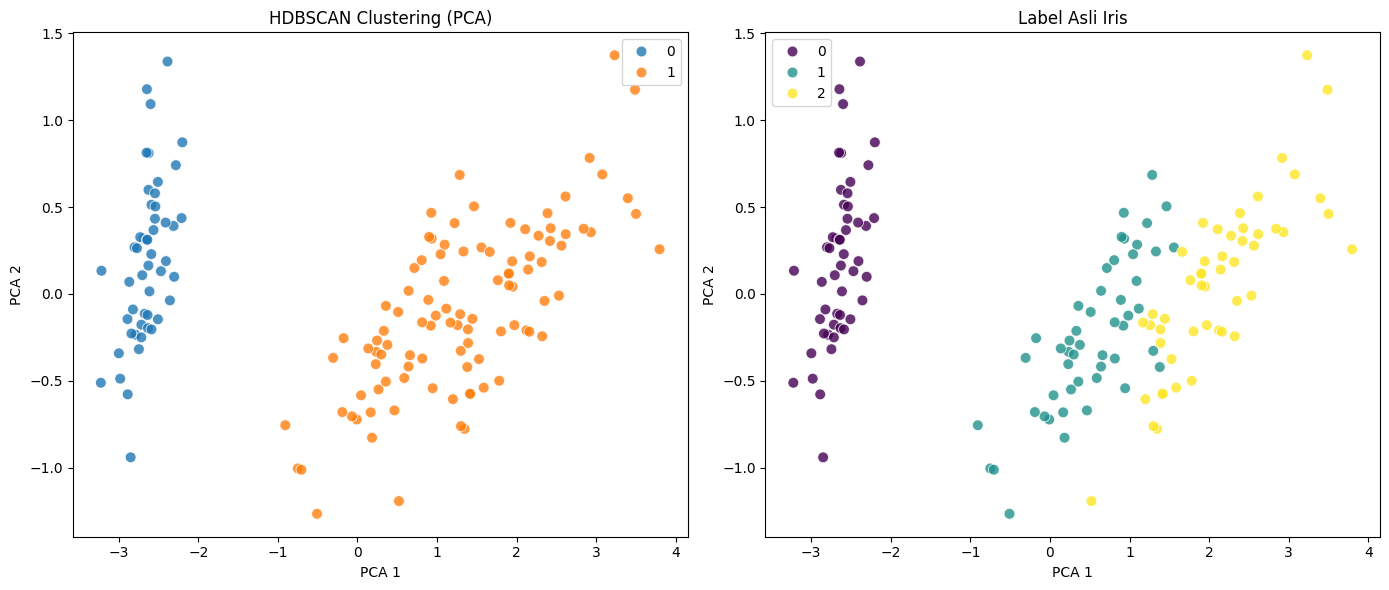

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import HDBSCAN
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA

# 1. Load Iris dataset
iris = load_iris()
X = iris.data
y_true = iris.target

# 2. Lakukan klasterisasi dengan HDBSCAN
hdb = HDBSCAN(min_cluster_size=15, min_samples=5)
labels = hdb.fit_predict(X)

# 3. Laporkan hasil (Jumlah klaster dan noise)
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = np.sum(labels == -1)

print(f"Jumlah klaster: {n_clusters}")
print(f"Jumlah noise: {n_noise}")
print(f"Label unik: {set(labels)}")

# 4. Reduksi dimensi dengan PCA untuk visualisasi
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# 5. Plot hasil visualisasi
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot HDBSCAN
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels, palette='tab10', ax=axes[0], s=60, alpha=0.8)
axes[0].set_title("HDBSCAN Clustering (PCA)")
axes[0].set_xlabel("PCA 1")
axes[0].set_ylabel("PCA 2")

# Plot Label Asli
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_true, palette='viridis', ax=axes[1], s=60, alpha=0.8)
axes[1].set_title("Label Asli Iris")
axes[1].set_xlabel("PCA 1")
axes[1].set_ylabel("PCA 2")

plt.tight_layout()
plt.show()